# Домашнее задание. Занятие 11. Мидтерм, этап 1: от сырого файла к чистой таблице

**DataGroup. Курс AI Engineering. Неделя 6**

Это тетрадь вашего мидтерм-проекта. На этапе 1 (домашка занятия 11) вы заполняете разделы 0-9: выбираете датасет и доводите его до чистой таблицы с EDA. На этапе 2 (домашка занятия 12, сам мидтерм) продолжаете **эту же тетрадь**, разделы 10-16: признаки, утечка, baseline и README. Полное ТЗ с критериями и списком датасетов в файле `Midterm_TZ.md`.

**Как работать с тетрадью**

1. Откройте её в Google Colab: «Файл», затем «Загрузить блокнот». Сразу переименуйте в `project.ipynb`: под этим именем она будет лежать в репозитории.
2. **Первой запустите ячейку «Помощники»** ниже. Если перезапустили среду, запустите её снова.
3. Идите по разделам сверху вниз. В каждом разделе есть **«Что сделать»**, ссылка на часть тетради практики занятия 11, где это показано на отелях, пустые ячейки для кода и ячейка **«Вывод»**: её заполняете своими словами.
4. Каждое решение про данные записывайте в журнал: `log("шаг", "что решили", len(df))`.
5. В конце этапа запустите самопроверку (раздел 9), потом «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь должна пройти без ошибок.
6. Загрузите тетрадь и файлы в публичный репозиторий на GitHub и сдайте **ссылку на репозиторий** в LMS. Как загрузить, в разделе 9 и в ТЗ.

**Баллы этапа 1: 100.**

| раздел | баллы |
|---|---|
| 0-1. Карточка проекта и первый взгляд | 10 |
| 2-3. Дубли и невозможные значения | 15 |
| 4. Пропуски | 20 |
| 5-6. Типы, даты и выбросы | 15 |
| 7. EDA: 5 графиков с выводами | 20 |
| 8. Функция `clean`, сторожа, журнал, чистый CSV | 10 |
| 9. Репозиторий: публичный, тетрадь с выводами | 10 |

**Данные.** Один датасет из списка в ТЗ или свой, согласованный в чате группы. Вот список коротко, ссылки и подробности в ТЗ:

| датасет | задача | уровень |
|---|---|---|
| клиенты телеком-компании (Telco) | классификация: уйдёт ли клиент | базовый |
| поездки на такси в Нью-Йорке | регрессия: чаевые или стоимость | базовый |
| рейтинги шоколада | регрессия: оценка плитки | базовый |
| банк: телемаркетинг вкладов | классификация: откроет ли вклад | средний |
| восхождения в Гималаях | классификация: дойдёт ли до вершины | средний |
| Airbnb в Нью-Йорке | регрессия: цена ночи | средний |
| песни Spotify | регрессия: популярность трека | средний |
| мебель IKEA | регрессия: цена | средний |
| оценки кофе | регрессия: итоговая оценка | продвинутый |
| дома в Эймсе | регрессия: цена дома | продвинутый |

**Как устроено.** Проверки с баллами здесь нет: работу проверяет преподаватель по критериям из ТЗ. Решения принимаете вы, и главное в каждом разделе не код, а **вывод**: что вы увидели и почему решили именно так. Короткий честный вывод лучше длинного пересказа кода.

**Чем пользоваться.** Помощники ниже: `load_csv`, `passport`, `log` и `show_journal`, `target_plot`, `selfcheck`. Всё остальное из тетради практики занятия 11: её функции можно копировать и менять под свои данные.

**Если застряли.** Каждый раздел ссылается на часть тетради практики, где то же самое сделано на отелях. Задайте вопрос в чате группы, не дожидаясь срока. И ставьте `print` после каждого шага: почти всегда окажется, что в таблице лежит не то, что вы думали.

---
## Помощники

Запустите эту ячейку первой. Она подключает библиотеки и создаёт пять функций для проекта.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("project_data")
DATA.mkdir(exist_ok=True)
TEAL, ORANGE, RED, NAVY, GRAY = "#278071", "#E0843B", "#B0413E", "#13293E", "#8A94A0"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)


def load_csv(url, name="raw", **options):
    """Скачать CSV по ссылке один раз в папку project_data, дальше читать с диска."""
    path = DATA / f"{name}.csv"
    if not path.exists():
        urlretrieve(url, path)
    return pd.read_csv(path, **options)


def passport(table):
    """Паспорт данных: одна строка на столбец, тип, пропуски, разных значений, пример."""
    return pd.DataFrame({
        "тип": table.dtypes.astype(str),
        "пропусков": table.isna().sum(),
        "доля, %": (table.isna().mean() * 100).round(1),
        "разных": table.nunique(),
        "пример": table.iloc[0],
    })


journal = {}


def log(step, decision, rows):
    """Записать решение в журнал. Повторный запуск с тем же шагом перезаписывает запись."""
    journal[step] = {"решение": decision, "строк": rows}


def show_journal():
    """Журнал решений таблицей."""
    return pd.DataFrame(journal).T


def target_plot(table, groups, target, title, xlabel):
    """Цель по группам. Цель 0 и 1: доля единиц в процентах. Цель число: медиана."""
    is_class = set(table[target].dropna().unique()) <= {0, 1}
    stat = "mean" if is_class else "median"
    result = table.groupby(groups, observed=True)[target].agg([stat, "size"])
    values = result[stat] * 100 if is_class else result[stat]
    overall = table[target].mean() * 100 if is_class else table[target].median()
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    bars = ax.bar(result.index.astype(str), values, color=TEAL)
    ax.axhline(overall, color=ORANGE, ls="--", label="по всем данным")
    labels = ax.bar_label(bars, fmt="%.0f%%" if is_class else "%.1f", padding=2)
    for label in labels:
        label.set_bbox({"facecolor": "white", "edgecolor": "none", "pad": 1})
    ax.set_ylim(0, max(values.max(), overall) * 1.4)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"доля {target} = 1, %" if is_class else f"медиана {target}")
    ax.legend(loc="best")
    if len(result) > 6 or max(len(str(i)) for i in result.index) > 12:
        plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
    return result.round(3)


def selfcheck(raw_table, clean_table, target):
    """Самопроверка этапа 1: что готово, а что нет."""
    has_target = target in clean_table.columns
    checks = [
        ("цель есть в чистой таблице", has_target),
        ("цель без пропусков", has_target and bool(clean_table[target].notna().all())),
        ("цель числом: класс 0 и 1 или число", has_target and pd.api.types.is_numeric_dtype(clean_table[target])),
        ("в чистой таблице нет пропусков", int(clean_table.isna().sum().sum()) == 0),
        ("полных дублей нет (если есть, объясните в выводе)", not clean_table.duplicated().any()),
        ("осталось больше половины строк", len(clean_table) > len(raw_table) / 2),
        ("в журнале минимум 5 решений", len(journal) >= 5),
    ]
    for name, ok in checks:
        print(("OK   " if ok else "НЕТ  ") + name)
    print(f"строк: было {len(raw_table)}, стало {len(clean_table)}; столбцов: было {raw_table.shape[1]}, стало {clean_table.shape[1]}")


print("помощники готовы")

помощники готовы


---
# Этап 1. Домашка занятия 11

---
## 0. Карточка проекта  ·  вместе с разделом 1: 10 баллов

**Что сделать.** Заполните таблицу ниже (двойной щелчок по ячейке) и укажите ссылку и цель в коде. Пример карточки: часть 1 тетради практики, раздел 1.1.

| вопрос | ответ |
|---|---|
| датасет и ссылка на источник | Восхождения в Гималаях, участники экспедиций (Himalayan Database, TidyTuesday): [members.csv](https://github.com/rfordatascience/tidytuesday/tree/main/data/2020/2020-09-22) |
| что значит одна строка | один участник одной экспедиции: возраст, пол, гражданство, роль, гора, год и сезон |
| цель (столбец) | `success`: дошёл ли участник до вершины (1 дошёл, 0 нет) |
| тип задачи | классификация (да/нет) |
| метрика | доля верных ответов|
| кому и зачем нужен такой прогноз | агентствам и организаторам экспедиций: заранее оценить шансы участника, подобрать гору, сезон и поддержку (гиды, кислород), а в группе риска уделить больше внимания подготовке и безопасности |

In [2]:
DATA_URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-09-22/members.csv"
TARGET = "success" #дошёл ли участник до вершины

---
## 1. Первый взгляд

**Что сделать.**

* загрузить данные: `raw = load_csv(DATA_URL)`, посмотреть `shape` и `head`;
* паспорт данных: `passport(raw)`;
* распределение цели: для класса `value_counts()`, для числа `describe()` и гистограмма;
* если цель текстом («Yes» и «No»), превратить её в 0 и 1, например `(raw[TARGET] == "Yes").astype(int)`, и записать это в журнал.

Пример: часть 1 практики, разделы 1.1-1.4.

In [3]:
# загрузка, shape, head
raw = load_csv(DATA_URL)
print(raw.shape)
log("загрузка", "members.csv из tidytuesday, участники экспедиций", len(raw))
raw.head(3)


(76519, 21)


,expedition_id,member_id,peak_id,peak_name,year,season,sex,age,citizenship,expedition_role,hired,highpoint_metres,success,solo,oxygen_used,died,death_cause,death_height_metres,injured,injury_type,injury_height_metres
0,AMAD78301,AMAD78301-01,AMAD,Ama Dablam,1978,Autumn,M,40.0,France,Leader,False,NaN,False,False,False,False,NaN,NaN,False,NaN,NaN
1,AMAD78301,AMAD78301-02,AMAD,Ama Dablam,1978,Autumn,M,41.0,France,Deputy Leader,False,6000.0,False,False,False,False,NaN,NaN,False,NaN,NaN
2,AMAD78301,AMAD78301-03,AMAD,Ama Dablam,1978,Autumn,M,27.0,France,Climber,False,NaN,False,False,False,False,NaN,NaN,False,NaN,NaN


In [4]:
# паспорт данных
passport(raw)


,тип,пропусков,"доля, %",разных,пример
expedition_id,object,0,0.0,10350,AMAD78301
member_id,object,0,0.0,76518,AMAD78301-01
peak_id,object,0,0.0,391,AMAD
peak_name,object,15,0.0,390,Ama Dablam
year,int64,0,0.0,92,1978
season,object,0,0.0,5,Autumn
sex,object,2,0.0,2,M
age,float64,3497,4.6,74,40.0
citizenship,object,10,0.0,212,France
expedition_role,object,21,0.0,524,Leader


In [5]:
# цель: распределение, при необходимости в числа 0 и 1
print(raw[TARGET].value_counts())

df = raw.copy()
df[TARGET] = df[TARGET].astype(int)
print("доля успеха:", round(df[TARGET].mean(),3))
log("цель", "success: True/False to 1/0", len(df))
show_journal()

success
False    47320
True     29199
Name: count, dtype: int64
доля успеха: 0.382


,решение,строк
загрузка,"members.csv из tidytuesday, участники экспедиций",76519
цель,success: True/False to 1/0,76519


**Вывод.**
В данных 76 519 строк и 21 столбец, одна строка это один участник одной экспедиции.
В паспорте я заметил несколько проблем: `member_id` 76 518 разных значений при 76 519 строках, значит, один номер повторяется; `season` 5 значений, хотя сезонов 4, похоже на скрытый пропуск.
Столбцы `death_cause`, `death_height_metres`, `injury_type` и `injury_height_metres` пусты на 98%, но это скорее «нет», чем «не знаем»: причины смерти нет у тех, кто не погиб. Ещё есть пропуски в `age` (4,6%) и `highpoint_metres` (28,5%), а `highpoint_metres` вместе с `died`, `injured` известны только после экспедиции, это будущая утечка. До вершины дошли 29 199 участников из 76 519, это 38,2%, поэтому пустышка «никто не дойдёт» уже угадывает 61,8%.

---
## 2. Дубли  ·  вместе с разделом 3: 15 баллов

**Что сделать.**

* сколько полных дублей: `raw.duplicated().sum()`;
* если в данных есть номер записи (id), то и повторы по нему: `duplicated(subset=["..."])`;
* посмотреть на несколько дублей глазами (`keep=False`) и решить, что это: ошибка выгрузки, одна запись в нескольких местах или разные настоящие строки;
* записать решение в журнал.

Пример: часть 2 практики, разделы 2.1-2.4.

In [6]:
# сколько дублей, какие они
print("полных дублей", df.duplicated().sum())

print("повторов member_id:", df["member_id"].duplicated().sum())

no_id = df.drop(columns="member_id")
print("oдинаковых строк без member_id:", no_id.duplicated().sum())



полных дублей 0
повторов member_id: 1
oдинаковых строк без member_id: 4680


In [7]:
same_id = df[df["member_id"].duplicated(keep=False)]
same_id[["expedition_id", "member_id", "year", "citizenship", "age", "expedition_role"]]
display(same_id)

#два разных человека можно понять через 'age', 'citizenship', 'уear'

df[df["expedition_id"]== "KANG10101"]["year"].value_counts() #100 лет между экспеции поэтому повторяется номер member_id


,expedition_id,member_id,peak_id,peak_name,year,season,sex,age,citizenship,expedition_role,hired,highpoint_metres,success,solo,oxygen_used,died,death_cause,death_height_metres,injured,injury_type,injury_height_metres
22019,KANG10101,KANG10101-01,KANG,Kangchenjunga,1910,Spring,M,41.0,UK,Leader,False,NaN,0,False,False,False,NaN,NaN,False,NaN,NaN
50986,KANG10101,KANG10101-01,KANG,Kangchenjunga,2010,Spring,M,53.0,S Korea,Leader,False,NaN,0,False,False,False,NaN,NaN,False,NaN,NaN


,count
year,
2010,6
1910,1


In [8]:
same_person = df[no_id.duplicated(keep=False)]
print("строки одинаковых:", len(same_person))

print("роли:", same_person["expedition_role"].value_counts().head(5).to_dict())
print("гражданство:", same_person["citizenship"].value_counts().head(5).to_dict())

print("наняты:", round(same_person["hired"].mean(),2), "во всей таблице:", round(df["hired"].mean(), 2))

same_person.sort_values(["expedition_id", "age"]).head(10)

строки одинаковых: 8285
роли: {'Climber': 5189, 'H-A Worker': 2568, 'H-A Assistant': 217, 'Member': 40, 'Climber (torch)': 28}
гражданство: {'Nepal': 2723, 'Japan': 888, 'China': 737, 'India': 462, 'UK': 398}
наняты: 0.34 во всей таблице: 0.21


,expedition_id,member_id,peak_id,peak_name,year,season,sex,age,citizenship,expedition_role,hired,highpoint_metres,success,solo,oxygen_used,died,death_cause,death_height_metres,injured,injury_type,injury_height_metres
27271,AMAD00102,AMAD00102-02,AMAD,Ama Dablam,2000,Spring,M,35.0,Russia,Climber,False,6814.0,1,False,False,False,NaN,NaN,False,NaN,NaN
27275,AMAD00102,AMAD00102-05,AMAD,Ama Dablam,2000,Spring,M,35.0,Russia,Climber,False,6814.0,1,False,False,False,NaN,NaN,False,NaN,NaN
27305,AMAD00111,AMAD00111-02,AMAD,Ama Dablam,2000,Spring,M,22.0,Mexico,Climber,False,6200.0,0,False,False,False,NaN,NaN,False,NaN,NaN
27306,AMAD00111,AMAD00111-03,AMAD,Ama Dablam,2000,Spring,M,22.0,Mexico,Climber,False,6200.0,0,False,False,False,NaN,NaN,False,NaN,NaN
28868,AMAD00301,AMAD00301-04,AMAD,Ama Dablam,2000,Autumn,M,31.0,Italy,Climber,False,6814.0,1,False,False,False,NaN,NaN,False,NaN,NaN
28869,AMAD00301,AMAD00301-05,AMAD,Ama Dablam,2000,Autumn,M,31.0,Italy,Climber,False,6814.0,1,False,False,False,NaN,NaN,False,NaN,NaN
28887,AMAD00305,AMAD00305-05,AMAD,Ama Dablam,2000,Autumn,M,44.0,Italy,Climber,False,6814.0,1,False,False,False,NaN,NaN,False,NaN,NaN
28890,AMAD00305,AMAD00305-08,AMAD,Ama Dablam,2000,Autumn,M,44.0,Italy,Climber,False,6814.0,1,False,False,False,NaN,NaN,False,NaN,NaN
28886,AMAD00305,AMAD00305-04,AMAD,Ama Dablam,2000,Autumn,M,53.0,Italy,Climber,False,6814.0,1,False,False,False,NaN,NaN,False,NaN,NaN
28888,AMAD00305,AMAD00305-06,AMAD,Ama Dablam,2000,Autumn,M,53.0,Italy,Climber,False,6814.0,1,False,False,False,NaN,NaN,False,NaN,NaN


In [9]:
# решение: df = ... ; log(...)
df = df.drop_duplicates()
log("дубли", "полных дублей 0, 4680 совпадений без 'member_id' оставлены потому что разные люди;" "повтор KANG10101-01 это два разных человека 1910 и 2010 года", len(df))
print(df.shape)
show_journal()

(76519, 21)


,решение,строк
загрузка,"members.csv из tidytuesday, участники экспедиций",76519
цель,success: True/False to 1/0,76519
дубли,"полных дублей 0, 4680 совпадений без 'member_i...",76519


**Вывод.** Полных дублей нет. Номер участника `member_id` повторяется один раз `KANG10101-01` встречается в 1910 и в 2010 году у разных людей (UK, 41 год и S Korea, 53 года). Это не дубль ошибка в системе номеров год в номере экспедиции записан двумя цифрами поэтому 1910 и 2010 дали одинаковый номер. Обе строки оставляю. Если убрать номер участника совпадают 4 680 строк. Я посмотрел на них это участники одной экспедиции с одинаковыми возрастом, страной, ролью и высотой, но с разными номерами, то есть разные люди. Среди них много нанятых высотных работников из Непала нанятых 34% против 21% во всей таблице о них в базе записано мало поэтому строки совпадают. Удалить их значило бы потерять настоящих участников поэтому оставляю.

---
## 3. Невозможные значения и скрытые пропуски

**Что сделать.**

* написать функцию `check_rules(d)`, которая возвращает таблицу флагов: минимум 3 правила здравого смысла (отрицательная цена, ноль там, где ноль невозможен, возраст 150 лет);
* посмотреть на нарушителей глазами и решить по каждому правилу: удалить, исправить или оставить;
* найти скрытые пропуски: `value_counts()` по текстовым столбцам, `describe()` по числовым. Ищите `unknown`, `Undefined`, `?`, пробел, `999`, нули там, где их не бывает;
* записать решения в журнал.

Пример: часть 2 практики, разделы 2.5-2.7.

In [10]:
def check_rules(d):
    """Таблица флагов: True там, где строка нарушает правило."""
    return pd.DataFrame({
        "возраст меньше 10 или больше 90": (d["age"] < 10) | (d["age"] > 90),
        "высота больше Эвереста": d["highpoint_metres"] > 8850,
        "умер без причины": d["died"] & d["death_cause"].isna(),
        "травма без типа": d["injured"] & d["injury_type"].isna(),
        "поднялся но нет высоты": d["success"].astype(bool) & d["highpoint_metres"].isna(),
        "соло но нанят": d["solo"] & d["hired"],
    })
check_rules(df)

,возраст меньше 10 или больше 90,высота больше Эвереста,умер без причины,травма без типа,поднялся но нет высоты,соло но нанят
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,False,False,False,False
3,False,False,False,False,False,False
4,False,False,False,False,False,False
...,...,...,...,...,...,...
76514,False,False,False,False,False,False
76515,False,False,False,False,False,False
76516,False,False,False,False,False,False
76517,False,False,False,False,False,False


In [11]:
# сколько нарушений по каждому правилу, нарушители глазами
flags = check_rules(df)
print(flags.sum())


возраст меньше 10 или больше 90    1
высота больше Эвереста             0
умер без причины                   0
травма без типа                    1
поднялся но нет высоты             0
соло но нанят                      3
dtype: int64


In [12]:
bad = flags.any(axis='columns')
cols = ["expedition_id", "peak_name", "year", "age", "sex", "expedition_role","citizenship", "hired", "solo", "success", "injured", "injury_type"]
df[bad][cols]

,expedition_id,peak_name,year,age,sex,expedition_role,citizenship,hired,solo,success,injured,injury_type
18609,MANA84302,Manaslu,1984,7.0,F,Member,Italy,False,False,0,False,NaN
20729,PUMO96105,Pumori,1996,32.0,M,Climber,Czech Republic,False,False,0,True,NaN
49219,MANA09120,Manaslu,2009,39.0,M,H-A Worker,Nepal,True,True,0,False,NaN
55620,KANG12101,Kangchenjunga,2012,23.0,M,H-A Worker,Nepal,True,True,0,False,NaN
62951,HIML14303,Himlung Himal,2014,29.0,M,H-A Worker,Nepal,True,True,1,False,NaN


In [13]:
kid_with_who = df.loc[df["age"] == 7, "expedition_id"].iloc[0]
df[df["expedition_id"] == kid_with_who][["member_id", "age", "sex", "expedition_role", "citizenship"]]

,member_id,age,sex,expedition_role,citizenship
18607,MANA84302-02,28.0,F,Climber,Italy
18608,MANA84302-03,32.0,M,Exp Doctor,Italy
18609,MANA84302-04,7.0,F,Member,Italy
18610,MANA84302-01,34.0,M,Leader,Italy
18611,MANA84302-05,27.0,M,Climber,Switzerland
18612,MANA84302-06,30.0,M,Climber,Switzerland
18613,MANA84302-07,36.0,F,Climber,Italy
18614,MANA84302-08,37.0,M,Climber,Switzerland
18615,MANA84302-09,24.0,M,Climber,Switzerland


In [14]:
# скрытые пропуски: value_counts и describe
skip = ["expedition_id", "member_id", "peak_id", "peak_name", "citizenship", "expedition_role"]

for col in df.select_dtypes(exclude="number").columns:
  if col in skip:
    continue
  print(col, df[col].value_counts().to_dict())


season {'Spring': 37782, 'Autumn': 35895, 'Winter': 2101, 'Summer': 740, 'Unknown': 1}
sex {'M': 69473, 'F': 7044}
hired {False: 60788, True: 15731}
solo {False: 76398, True: 121}
oxygen_used {False: 58286, True: 18233}
died {False: 75413, True: 1106}
death_cause {'Avalanche': 369, 'Fall': 331, 'AMS': 102, 'Illness (non-AMS)': 60, 'Disappearance (unexplained)': 49, 'Exposure / frostbite': 42, 'Exhaustion': 41, 'Other': 33, 'Crevasse': 27, 'Falling rock / ice': 26, 'Icefall collapse': 16, 'Unknown': 10}
injured {False: 74806, True: 1713}
injury_type {'Exposure / frostbite': 599, 'AMS': 415, 'Illness (non-AMS)': 257, 'Fall': 117, 'Avalanche': 114, 'Falling rock / ice': 88, 'Other': 75, 'Crevasse': 25, 'Disappearance (unexplained)': 8, 'Icefall collapse': 7, 'Exhaustion': 7}


In [15]:
for col in ["citizenship", "expedition_role"]:
    print(col, "| разных значений:", df[col].nunique())
    print(df[col].value_counts().head(20).to_dict())


citizenship | разных значений: 212
{'Nepal': 16135, 'USA': 6448, 'Japan': 6432, 'UK': 5219, 'France': 4611, 'Spain': 3326, 'S Korea': 2913, 'Italy': 2764, 'Germany': 2661, 'Switzerland': 2458, 'China': 2285, 'Austria': 2137, 'India': 2013, 'Australia': 1416, 'Poland': 1404, 'Russia': 1335, 'Canada': 1127, 'New Zealand': 806, 'W Germany': 784, 'Netherlands': 744}
expedition_role | разных значений: 524
{'Climber': 44667, 'H-A Worker': 14489, 'Leader': 10036, 'Exp Doctor': 1450, 'Deputy Leader': 1238, 'Sirdar': 579, 'H-A Assistant': 391, 'BC Manager': 385, 'Climbing Leader': 356, 'Member': 333, 'Co-Leader': 331, 'Film Team': 143, 'Climbing Guide': 121, 'Cameraman': 110, 'Journalist': 59, 'Climber (torch)': 49, 'Scientist': 46, 'Climber (S)': 37, 'Leader/Exp Doctor': 37, 'Support': 34}


In [16]:
df["citizenship"].value_counts().tail(10)

,count
citizenship,
Venezuela/Spain,1
Chile/Sweden,1
Kyrgyz Republic,1
Syria,1
Egypt,1
UK/Iceland,1
Botswana,1
Serbia/Jordan,1
Netherlands/Switzerland,1


In [17]:
dual = df["citizenship"].str.contains("/", na=False)
print("люди с двойным гражданством:", dual.sum())
print("разных пар стран:", df.loc[dual, "citizenship"].nunique())

люди с двойным гражданством: 300
разных пар стран: 95


In [18]:
names = df["citizenship"].dropna().unique()
single = []
for name in names:
    if "/" not in name:
        single.append(name)

print("одиночных стран:", len(single))
print(sorted(single))

одиночных стран: 117
['Albania', 'Algeria', 'Andorra', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Bangladesh', 'Belarus', 'Belgium', 'Bhutan', 'Bolivia', 'Bosnia-Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Canada', 'Chile', 'China', 'Colombia', 'Costa Rica', 'Croatia', 'Cyprus', 'Czech Republic', 'Czechoslovakia', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'Estonia', 'Finland', 'France', 'Georgia', 'Germany', 'Greece', 'Guatemala', 'Hong Kong', 'Hungary', 'Iceland', 'India', 'India?', 'Indonesia', 'Iran', 'Ireland', 'Israel', 'Italy', 'Japan', 'Jordan', 'Kazakhstan', 'Kenya', 'Kosovo', 'Kuwait', 'Kyrgyz Republic', 'Kyrgyzstan', 'Latvia', 'Lebanon', 'Liechtenstein', 'Lithuania', 'Luxembourg', 'Macedonia', 'Malaysia', 'Malta', 'Mauritius', 'Mexico', 'Moldova', 'Mongolia', 'Montenegro', 'Morocco', 'Myanmar', 'N Korea', 'Nepal', 'Netherlands', 'New Zealand', 'Norway', 'Oman', 'Pakistan', 'Palestine', 'Panama', 'Peru', 'Philippines', 'Poland', '

In [19]:
df["citizenship"] = df["citizenship"].replace("Kyrgyz Republic", "Kyrgyzstan")
print("Kyrgyzstan:", (df["citizenship"] == "Kyrgyzstan").sum())


Kyrgyzstan: 14


In [20]:
df.describe()

,year,age,highpoint_metres,success,death_height_metres,injury_height_metres
count,76519.000000,73022.000000,54686.000000,76519.000000,1068.000000,1009.000000
mean,2000.361714,37.334297,7470.680759,0.381592,6592.850187,7049.913776
std,14.780560,10.395602,1040.063830,0.485780,1308.186282,1214.244710
min,1905.000000,7.000000,3800.000000,0.000000,400.000000,400.000000
25%,1991.000000,29.000000,6700.000000,0.000000,5800.000000,6200.000000
50%,2004.000000,36.000000,7400.000000,0.000000,6600.000000,7100.000000
75%,2012.000000,44.000000,8400.000000,1.000000,7550.000000,8000.000000
max,2019.000000,85.000000,8850.000000,1.000000,8830.000000,8880.000000


In [21]:
# решения и журнал
log("невозможное", "6 правил, 5 строк с нарушениями: все оставлены, редкие случаи или мелкие ошибки", len(df))
log("страны", "212 значений: 95 пар двойного гражданства (300 чел.) оставлены; Kyrgyz Republic поменял на Kyrgyzstan", len(df))
df = df[df["season"] != "Unknown"]
log("скрытые пропуски", "сезон Unknown: 1 строка удалена; death_cause Unknown (10) оставлен", len(df))
print(df.shape)
print(df["season"].value_counts().to_dict())
show_journal()

(76518, 21)
{'Spring': 37782, 'Autumn': 35895, 'Winter': 2101, 'Summer': 740}


,решение,строк
загрузка,"members.csv из tidytuesday, участники экспедиций",76519
цель,success: True/False to 1/0,76519
дубли,"полных дублей 0, 4680 совпадений без 'member_i...",76519
невозможное,"6 правил, 5 строк с нарушениями: все оставлены...",76519
страны,212 значений: 95 пар двойного гражданства (300...,76519
скрытые пропуски,сезон Unknown: 1 строка удалена; death_cause U...,76518


**Вывод.** Я написал 6 правил:
Два на диапазон возраст от 10 до 90 лет и высшая точка не выше 8850 м, это высшая точка Гималаев, Эверест
Четыре на согласованность 1 погиб но нет причины; 2 травма но нет типа; 3 дошёл но нет высоты; 4 соло но нанят. Нарушений 5 строк. Возраст 7 лет это девочка итальянской экспедиции на Манаслу 1984 года ролью Member, остальные участники взрослые. Похоже ребёнок одного из них это редкость оставил. Трое нанятых шерпов отмечены как соло ошибка в одном флаге оставил. У одного участника травма без типа тип просто не записан оставил.
Скрытые пропуски:
`season` одна строка `Unknown` сезон не угадать удалил её.
`death_cause` 10 раз `Unknown` так и оставил это может честное «причина неизвестна» оставил. В числах нулей и `999` нет.
Страны - меня смутило что стран 212, а в мире их около 193. Посмотрел самые редкие значения и увидел двойное гражданство через '/' - 300 человек и 95 разных пар каждая пара считалась отдельной страной. Без пар осталось 117 стран. В списке нашёл `Kyrgyz Republic` и `Kyrgyzstan` это одна страна, объединил. Ещё есть `India?` составители может не были уверены и страны которых уже нет (USSR, W Germany, Yugoslavia) так как данные с 1905 года тогда они существовали поэтому оставил.

---
## 4. Пропуски  ·  20 баллов

**Что сделать.**

* для каждого столбца с пропусками сравнить цель у строк с пропуском и без: `df.groupby(df[col].isna())[TARGET].mean()`;
* решить, что значит пропуск: «не знаем» или «нет»;
* заполнить: «нет» по смыслу (0, «нет»), «не знаем» медианой, самым частым или категорией `Unknown`; если пропуск говорит о строке, сначала флаг; если пропусков больше половины, флаг и удалить столбец;
* заполнить таблицу решений ниже и записать решения в журнал.

По желанию, без баллов: проверить способ заполнения на известных значениях, как в разделе 3.4 практики.

Пример: часть 3 практики.

In [22]:
# где пропуски и сколько
missing = df.isna().sum()
missing = missing[missing > 0]
print(pd.DataFrame({
    "пропусков": missing,
    "доля, %": (missing / len(df)*100).round(1)
}))

                      пропусков  доля, %
peak_name                    15      0.0
sex                           1      0.0
age                        3496      4.6
citizenship                  10      0.0
expedition_role              21      0.0
highpoint_metres          21833     28.5
death_cause               75412     98.6
death_height_metres       75450     98.6
injury_type               74806     97.8
injury_height_metres      75509     98.7


In [23]:
# пропуск как информация: цель у строк с пропуском и без
for col in missing.index:
  result = df.groupby(df[col].isna())[TARGET].agg(["mean","size"]).round(3)
  print(result, end='\n\n')


            mean   size
peak_name              
False      0.381  76503
True       0.933     15

        mean   size
sex                
False  0.382  76517
True   1.000      1

        mean   size
age                
False  0.385  73022
True   0.318   3496

              mean   size
citizenship              
False        0.382  76508
True         0.000     10

                  mean   size
expedition_role              
False            0.382  76497
True             0.143     21

                   mean   size
highpoint_metres              
False             0.534  54685
True              0.000  21833

              mean   size
death_cause              
False        0.215   1106
True         0.384  75412

                      mean   size
death_height_metres              
False                0.217   1068
True                 0.384  75450

              mean   size
injury_type              
False        0.234   1712
True         0.385  74806

                       mean   size
injury_h

In [24]:
print("медианный год:", df.groupby(df["age"].isna())["year"].median().to_dict())
print("доля нанятых:", df.groupby(df["age"].isna())["hired"].mean().round(2).to_dict())

медианный год: {False: 2004.0, True: 1988.0}
доля нанятых: {False: 0.19, True: 0.5}


In [25]:
print(pd.crosstab(df["died"], df["death_cause"].isna()), end="\n\n")

print(pd.crosstab(df["injured"], df["injury_type"].isna()))

death_cause  False  True 
died                     
False            0  75412
True          1106      0

injury_type  False  True 
injured                  
False            0  74805
True          1712      1


In [26]:
# заполнение и журнал

df["age_missing"] = df["age"].isna().astype(int)
df["age"] = df["age"].fillna(df["age"].median())
log("пропуски: возраст", "age: 3496 (4,6%), флаг age_missing, заполняй медианой", len(df))

df["peak_name"] = df["peak_name"].fillna(df["peak_id"])
df["sex"] = df["sex"].fillna("M")
df["citizenship"] = df["citizenship"].fillna("Unknown")
df["expedition_role"] = df["expedition_role"].fillna("Unknown")
log("пропуски: единичные", "peak_name по peak_id (15); sex взял - M (1); citizenship и role - Unknown (10 и 21)", len(df))

df["highpoint_metres"] = df["highpoint_metres"].fillna(0)
log("пропуски: высота", "highpoint_metres: 21833 (28,5%) - 0; известна только после экспедиции", len(df))

df = df.drop(columns=["death_cause", "death_height_metres", "injury_type", "injury_height_metres"])
log("пропуски: смерть и травмы", "4 столбца пусты на 98% = не погиб / без травмы, флаги died и injured есть - поэтому удалены", len(df))

print("пропусков осталось:", df.isna().sum().sum())
print(df.shape)

пропусков осталось: 0
(76518, 18)


| столбец | пропусков | «не знаем» или «нет» | что делаем | почему |
|---|---|---|---|---|
| `age` | 3 496 (4,6%) | не знаем | флаг `age_missing`, затем медиана 36 | возраст есть у каждого, но не записан; чаще у старых экспедиций и нанятых, успех у них ниже (31,8% против 38,5%), поэтому флаг |
| `peak_name` | 15 | не знаем | берём из `peak_id` | код горы есть, название восстанавливается по нему |
| `sex` | 1 | не знаем | самое частое: `M` | один пропуск, 91% участников мужчины |
| `citizenship` | 10 | не знаем | категория `Unknown` | выдумать страну не нужно |
| `expedition_role` | 21 | не знаем | категория `Unknown` | выдумать роль не нужно |
| `highpoint_metres` | 21 833 (28,5%) | не записано | 0 | при пропуске успеха нет ни разу; известна только после экспедиции |
| `death_cause`, `death_height_metres` | 98,6% | нет: не погиб | удаляем столбцы | пусто ровно у тех, кто не погиб; флаг `died` уже есть |
| `injury_type`, `injury_height_metres` | 97,8-98,7% | нет: без травмы | удаляем столбцы | пусто у тех, кто без травмы; флаг `injured` уже есть |

**Вывод.** Пропуски были в 10 столбцах. Четыре столбца про смерть и травмы пусты на 98% но это не «не знаем», а «нет»: `crosstab` показал, что причина смерти пуста ровно у тех кто не погиб. Флаги `died` и `injured` в данных уже есть поэтому эти столбцы удалил. Возраст не записан у 4,6% участников, чаще всего в старых экспедициях (медианный год 1988 против 2004) и у нанятых шерпов (50% против 19%). Успех у них ниже: 31,8% против 38,5%, значит, пропуск говорит о человеке, поэтому сначала сделал флаг `age_missing`, а потом заполнил медианой 36. Самая подозрительная находка это `highpoint_metres`: при пропуске успеха нет ни разу из 21 833 строк. Высота известна только после экспедиции, это утечка. Единичные пропуски в названии горы, поле, стране и роли заполнил по связанному столбцу, самым частым значением или категорией `Unknown`. Пропусков в таблице не осталось.

---
## 5. Типы и даты  ·  вместе с разделом 6: 15 баллов

**Что сделать.**

* числа, записанные текстом, превратить в числа: `pd.to_numeric(s, errors="coerce")`, и посмотреть, что попало в пропуски;
* текст с единицами («76%», «SR 1,385», «1800-2200») разобрать: `str.replace`, `str.extract`;
* даты превратить в даты: `pd.to_datetime`, и достать из них признаки: месяц, день недели, час, разницу дат;
* показать `dtypes` после исправлений.

Если в ваших данных нет ни дат, ни чисел текстом, напишите это в выводе: так тоже бывает.

Пример: часть 4 практики, разделы 4.1-4.3.

In [27]:
df.dtypes

,0
expedition_id,object
member_id,object
peak_id,object
peak_name,object
year,int64
season,object
sex,object
age,float64
citizenship,object
expedition_role,object


In [28]:
print("дробных возрастов:", (df["age"] % 1 != 0).sum())
print("дробных высот:", (df["highpoint_metres"] % 1 != 0).sum())

дробных возрастов: 0
дробных высот: 0


In [29]:
df["age"] = df["age"].astype(int)
df["highpoint_metres"] = df["highpoint_metres"].astype(int)
print(df[["age", "highpoint_metres"]].dtypes)

age                 int64
highpoint_metres    int64
dtype: object


In [30]:
bool_cols = ["hired", "solo", "oxygen_used", "died", "injured"]
for col in bool_cols:
    df[col] = df[col].astype(int)
print(df[bool_cols].dtypes)

hired          int64
solo           int64
oxygen_used    int64
died           int64
injured        int64
dtype: object


In [31]:
# даты
print("годы:", df["year"].min(), "-", df["year"].max())
print("сезоны:", df["season"].value_counts().to_dict())

годы: 1905 - 2019
сезоны: {'Spring': 37782, 'Autumn': 35895, 'Winter': 2101, 'Summer': 740}


In [32]:
log("типы", "чисел текстом нет; age и highpoint_metres - int (пропусков нет); 5 столбцов True/False - 1/0; даты нет", len(df))
df.dtypes

,0
expedition_id,object
member_id,object
peak_id,object
peak_name,object
year,int64
season,object
sex,object
age,int64
citizenship,object
expedition_role,object


**Вывод.** Чисел записанных текстом в данных нет все текстовые столбцы это номера, названия и категории (`season`, `sex`, `citizenship`, `expedition_role`).
`age` и `highpoint_metres` были дробными `float64` только из-за пропусков так как NaN бывает только в дробных числах перевёл их в `int`. Пять столбцов True/False `hired`, `solo`, `oxygen_used`, `died`, `injured` перевёл в 1/0 как и цель `success` так все «да/нет» записаны одинаково.
Даты в данных нет есть только год 1905-2019, уже число и сезон как категория, поэтому месяц или день недели достать невозможно.

---
## 6. Выбросы

**Что сделать.**

* для главных числовых столбцов найти кандидатов в выбросы: граница IQR или процентили (`quantile(0.999)`);
* по каждому решить: ошибка (удалить или исправить) или редкость (оставить, обрезать `clip`, сжать `np.log1p`);
* для длинного хвоста показать гистограммы до и после логарифма;
* записать решения в журнал.

Пример: часть 4 практики, разделы 4.4-4.6.

In [33]:
# кандидаты в выбросы
for col in ["age", "year", "highpoint_metres"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    lower = q1 - 1.5 * (q3 - q1)
    upper = q3 + 1.5 * (q3 - q1)
    print(col, "| граница IQR:", round(lower, 1), "...", round(upper, 1),
          "| ниже:", (df[col] < lower).sum(),
          "| выше:", (df[col] > upper).sum(),
          "| min:", df[col].min(), "| max:", df[col].max())

age | граница IQR: 10.5 ... 62.5 | ниже: 1 | выше: 1353 | min: 7 | max: 85
year | граница IQR: 1959.5 ... 2043.5 | ниже: 1373 | выше: 0 | min: 1905 | max: 2019
highpoint_metres | граница IQR: -12250.5 ... 20417.5 | ниже: 0 | выше: 0 | min: 0 | max: 8850


In [34]:
old = df["age"] > 62
print("старше 62:", old.sum())
print("медианный год:", df.loc[old, "year"].median())
print("успех у них:", round(df.loc[old, TARGET].mean(), 3), " у всех:", round(df[TARGET].mean(), 3))
print("99,9% участников не старше:", df["age"].quantile(0.999))

старше 62: 1353
медианный год: 2010.0
успех у них: 0.203  у всех: 0.382
99,9% участников не старше: 74.0


In [35]:
early = df["year"] < 1960
print("до 1960:", early.sum())
print("успех до 1960:", round(df.loc[early, TARGET].mean(), 3), " после:", round(df.loc[~early, TARGET].mean(), 3))

до 1960: 1373
успех до 1960: 0.173  после: 0.385


скошенность до: 0.7  после log1p: 0.06


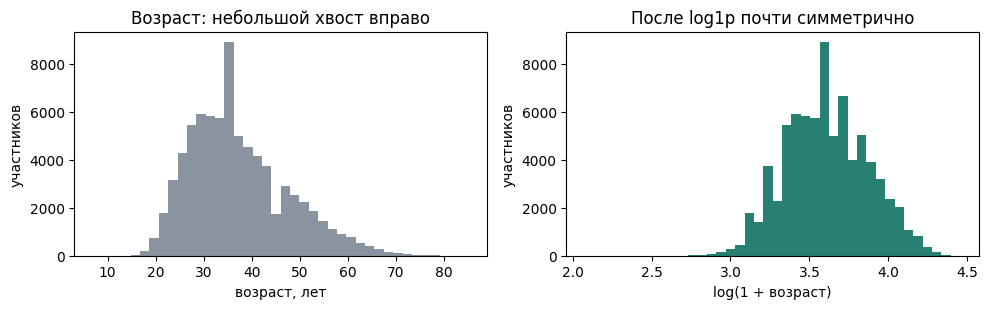

In [36]:
log_age = np.log1p(df["age"])
print("скошенность до:", round(df["age"].skew(), 2), " после log1p:", round(log_age.skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(df["age"], bins=40, color=GRAY)
axes[0].set_title("Возраст: небольшой хвост вправо")
axes[0].set_xlabel("возраст, лет")
axes[0].set_ylabel("участников")
axes[1].hist(log_age, bins=40, color=TEAL)
axes[1].set_title("После log1p почти симметрично")
axes[1].set_xlabel("log(1 + возраст)")
axes[1].set_ylabel("участников")
plt.tight_layout()
plt.show()

In [37]:
log("выбросы", "IQR: age >62 (1353) и year <1960 (1373) это реальные редкости оставлены"
    "логарифм возраста не нужен (скошенность 0,70); highpoint_metres не трогаем", len(df))

**Вывод.** По границе IQR нашёл два вида кандидатов. В `age` 1353 участника старше 62 лет: это в основном недавние экспедиции (медианный год 2010), успех у них около 20% против 38% у всех. Возраст до 85 лет в горах редкость, но реальная, а максимум 85 близок к 99,9-му процентилю (74), огромных единичных значений нет, поэтому оставил и не обрезал. В `year` 1373 участника экспедиций до 1960 года: это не ошибка, а история альпинизма (на Эверест впервые поднялись в 1953 году). Успех у ранних экспедиций около 16% против 39% позже, это тоже реальная информация. Ошибок среди выбросов нет, ничего не удалил. Логарифм для возраста проверил: скошенность 0,70 стала 0,06, но хвост и так небольшой (меньше 1), поэтому оставил возраст в годах, так понятнее. `highpoint_metres` не трогал: в нём нули от заполнения пропусков, и это столбец из будущего.

---
## 7. EDA: пять графиков  ·  20 баллов

**Что сделать.** Минимум 5 графиков. У каждого заголовок-вывод (не «lead_time и is_canceled», а «Чем раньше бронь, тем чаще отмена»), подписи осей с единицами и 1-3 предложения под графиком.

| график | на какой вопрос отвечает |
|---|---|
| распределение цели | какая доля классов или как распределено число |
| цель по 3-4 сильным признакам | что сильнее всего связано с целью |
| цель по времени или по группам | меняется ли картина по сезонам, городам, категориям |
| находка | что удивило: парадокс или подозрительно идеальный признак |

`target_plot(df, группы, TARGET, "заголовок-вывод", "подпись оси x")` рисует цель по группам. Числовой признак сначала разбейте на интервалы: `pd.cut(df["столбец"], [границы])`. Для двух числовых столбцов подойдёт `plt.scatter`.

Пример: часть 6 практики.

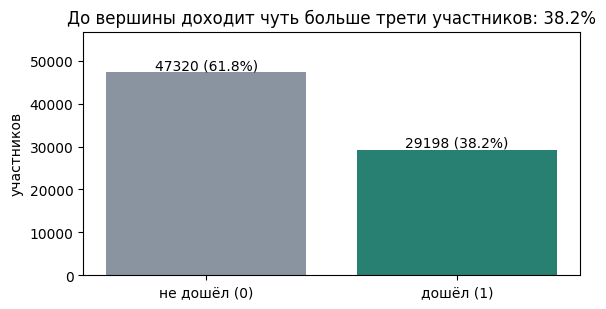

In [38]:
# график 1 распределение цели

counts = df[TARGET].value_counts().sort_index()
shares = (counts / len(df) * 100).round(1)

fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.bar(["не дошёл (0)", "дошёл (1)"], counts, color=[GRAY, TEAL])
ax.bar_label(bars, labels=[f"{c} ({s}%)" for c, s in zip(counts, shares)])
ax.set_title("До вершины доходит чуть больше трети участников: 38.2%")
ax.set_ylabel("участников")
ax.set_ylim(0, counts.max() * 1.2)
plt.tight_layout()
plt.show()

**Что видно на графике 1.** До вершины дошли 29 198 участников (38%), не дошли 47 320 (62%). Классы неравные: пустышка «никто не дойдёт» уже угадывает 62%, поэтому на этапе 2 модель нужно сравнивать с этим числом, а не с 50%.

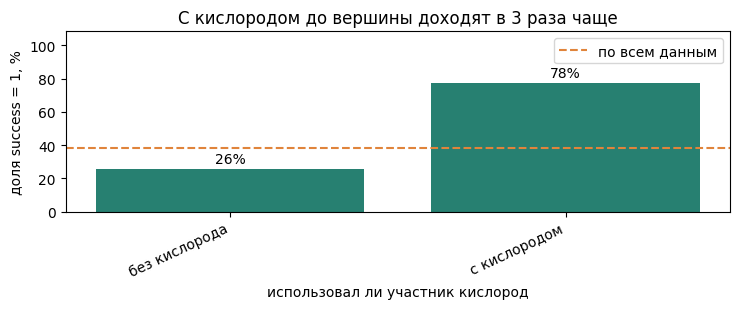

,mean,size
oxygen_used,,
без кислорода,0.259,58285
с кислородом,0.775,18233


In [39]:
# график 2 кислород

oxygen = df["oxygen_used"].map({0: "без кислорода", 1: "с кислородом"})
target_plot(df, oxygen, TARGET,
            "С кислородом до вершины доходят в 3 раза чаще",
            "использовал ли участник кислород")

**Что видно на графике 2.** Без кислорода до вершины доходят 26% участников, с кислородом 78%, это в 3 раза чаще. Кислородом пользуются в основном на самых высоких горах, где без него очень тяжело.

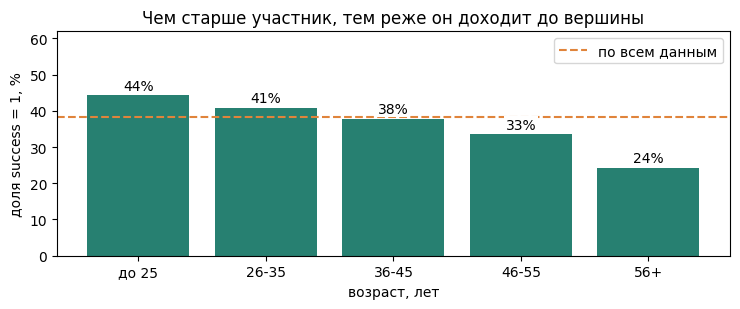

,mean,size
age,,
до 25,0.442,7909
26-35,0.408,27929
36-45,0.378,25289
46-55,0.335,10946
56+,0.242,4445


In [40]:
# график 3 успех по возрасту

age_band = pd.cut(df["age"], [0, 25, 35, 45, 55, 90],
                  labels=["до 25", "26-35", "36-45", "46-55", "56+"])
target_plot(df, age_band, TARGET,
            "Чем старше участник, тем реже он доходит до вершины",
            "возраст, лет")

**Что видно на графике 3.** До 25 лет до вершины доходят 44% участников, в 26-35 лет 41%, дальше доля падает с каждой группой: 38%, 34%, и после 55 лет только 24%. Возраст стабильно связан с успехом: молодым физически легче на большой высоте.

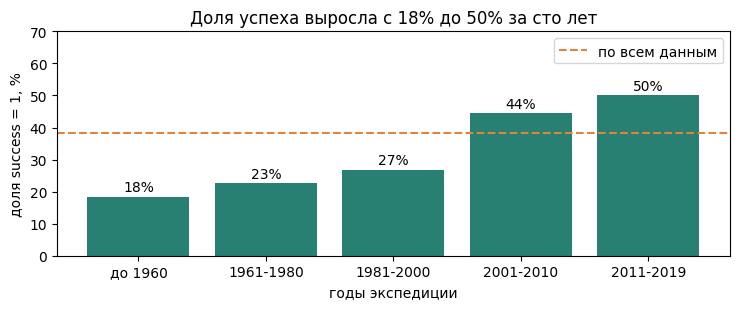

,mean,size
year,,
до 1960,0.183,1554
1961-1980,0.226,5537
1981-2000,0.269,25166
2001-2010,0.444,22026
2011-2019,0.500,22235


In [41]:
# график 4 успех по годам

year_band = pd.cut(df["year"], [1900, 1960, 1980, 2000, 2010, 2019],
                   labels=["до 1960", "1961-1980", "1981-2000", "2001-2010", "2011-2019"])
target_plot(df, year_band, TARGET,
            "Доля успеха выросла с 18% до 50% за сто лет",
            "годы экспедиции")

**Что видно на графике 4.** До 1960 года до вершины доходили 18% участников, в 1980-х и 1990-х 27%, а после 2010 года уже 50%. Успех растёт с каждым периодом: лучше снаряжение, точнее прогнозы погоды, провешенные верёвки и коммерческие экспедиции с гидами.

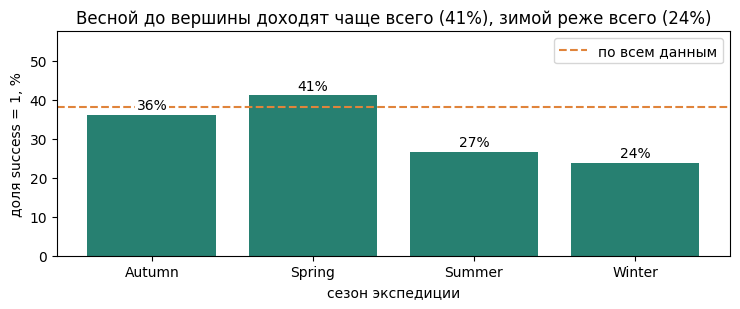

,mean,size
season,,
Autumn,0.361,35895
Spring,0.411,37782
Summer,0.266,740
Winter,0.238,2101


In [42]:
# график 5 успех по сезонам
target_plot(df, "season", TARGET,
            "Весной до вершины доходят чаще всего (41%), зимой реже всего (24%)",
            "сезон экспедиции")

**Что видно на графике 5.** Весной до вершины доходят 41% участников, осенью 36%, летом 27%, зимой только 24%. Почти все экспедиции идут весной и осенью. Летом в Гималаях муссон с дождями и снегопадами, а зимой сильный мороз и ветер, поэтому туда ходят редко и успех ниже. Но летних и зимних участников мало, поэтому их доли менее надёжны.

**Вывод по EDA.**
1. До вершины доходят 38% участников: пустышка «никто не дойдёт» даёт 62% верных, это пол для модели.
2. Кислород сильнее всего связан с успехом: с ним 78%, без него 26%. Но его нужно проверить на утечку на этапе 2.
3. Возраст: до 25 лет успех 44%, после 55 лет только 24%.
4. Время: доля успеха выросла с 18% до 1960 года до 50% после 2010 года.
5. Сезон: весной успех 41%, зимой 24%; почти все экспедиции идут весной и осенью.


---
## 8. Функция clean, сторожа и журнал  ·  10 баллов

**Что сделать.**

* собрать все решения разделов 2-6 в одну функцию `clean(raw_table)`: на входе сырая таблица, на выходе чистая;
* проверить, что `clean(raw)` даёт ту же таблицу, что пошаговая очистка;
* сторожа: `assert` на главные правила, например «нет пропусков», «нет невозможных значений»;
* показать журнал: `show_journal()`;
* сохранить чистые данные: `clean_df.to_csv("data/<имя>_clean.csv", index=False)`.

Пример: часть 9 практики, разделы 9.1-9.4.

In [43]:
def clean(raw_table):
    """Сырая таблица на входе, очищенная на выходе."""
    d = raw_table.copy()

    d["success"] = d["success"].astype(int)

    d = d.drop_duplicates()

    d = d[d["season"] != "Unknown"]
    d["citizenship"] = d["citizenship"].replace("Kyrgyz Republic", "Kyrgyzstan")

    d["age_missing"] = d["age"].isna().astype(int)
    d["age"] = d["age"].fillna(d["age"].median())
    d["peak_name"] = d["peak_name"].fillna(d["peak_id"])
    d["sex"] = d["sex"].fillna("M")
    d["citizenship"] = d["citizenship"].fillna("Unknown")
    d["expedition_role"] = d["expedition_role"].fillna("Unknown")
    d["highpoint_metres"] = d["highpoint_metres"].fillna(0)
    d = d.drop(columns=["death_cause", "death_height_metres", "injury_type", "injury_height_metres"])

    d["age"] = d["age"].astype(int)
    d["highpoint_metres"] = d["highpoint_metres"].astype(int)
    for col in ["hired", "solo", "oxygen_used", "died", "injured"]:
        d[col] = d[col].astype(int)

    return d

In [44]:
# clean_df = clean(raw); сравнение с пошаговой очисткой; сторожа assert

clean_df = clean(raw)
print("clean(raw) совпадает с пошаговой очисткой:", clean_df.equals(df))
print(clean_df.shape)

assert clean_df.isna().sum().sum() == 0, "есть пропуски"
assert set(clean_df[TARGET].unique()) == {0, 1}, "цель не 0 и 1"
assert not clean_df.duplicated().any(), "есть полные дубли"
assert set(clean_df["season"].unique()) == {"Spring", "Autumn", "Winter", "Summer"}, "лишний сезон"
assert clean_df["age"].between(0, 100).all(), "невозможный возраст"
assert (clean_df["highpoint_metres"] <= 8850).all(), "высота выше Эвереста"
assert "death_cause" not in clean_df.columns, "столбцы смерти не удалены"
print("сторожа молчат: всё в порядке")

clean(raw) совпадает с пошаговой очисткой: True
(76518, 18)
сторожа молчат: всё в порядке




**Вывод.** Все решения разделов 2-6 собраны в функцию `clean`: она даёт ту же таблицу, что пошаговая очистка (`equals` даёт `True`). Флаг `age_missing` создаётся до заполнения возраста, а `astype(int)` идёт после заполнения пропусков. Семь сторожей проверяют: нет пропусков, цель 0 и 1, нет дублей, только 4 сезона, возраст от 0 до 100, высота не выше Эвереста, столбцы смерти удалены. Чистые данные сохранены в `data/himalaya_clean.csv`: 76 518 строк, 18 столбцов.


In [45]:
show_journal()

,решение,строк
загрузка,"members.csv из tidytuesday, участники экспедиций",76519
цель,success: True/False to 1/0,76519
дубли,"полных дублей 0, 4680 совпадений без 'member_i...",76519
невозможное,"6 правил, 5 строк с нарушениями: все оставлены...",76519
страны,212 значений: 95 пар двойного гражданства (300...,76519
скрытые пропуски,сезон Unknown: 1 строка удалена; death_cause U...,76518
пропуски: возраст,"age: 3496 (4,6%), флаг age_missing, заполняй м...",76518
пропуски: единичные,peak_name по peak_id (15); sex взял - M (1); c...,76518
пропуски: высота,"highpoint_metres: 21833 (28,5%) - 0; известна ...",76518
пропуски: смерть и травмы,4 столбца пусты на 98% = не погиб / без травмы...,76518


In [46]:
Path("data").mkdir(exist_ok=True)
clean_df.to_csv("data/himalaya_clean.csv", index=False)
print("сохранено:", clean_df.shape)

сохранено: (76518, 18)


---
## 9. Самопроверка и репозиторий  ·  10 баллов

**Самопроверка.** Уберите `#` и запустите. Всё должно быть `OK`, а если где-то `НЕТ` по делу (например, дубли появились после обрезки выбросов, как в части 9 практики), объясните это в выводе.

In [47]:
selfcheck(raw, clean_df, TARGET)

OK   цель есть в чистой таблице
OK   цель без пропусков
OK   цель числом: класс 0 и 1 или число
OK   в чистой таблице нет пропусков
OK   полных дублей нет (если есть, объясните в выводе)
OK   осталось больше половины строк
OK   в журнале минимум 5 решений
строк: было 76519, стало 76518; столбцов: было 21, стало 18


**Репозиторий.**

1. github.com, справа вверху «+», затем «New repository». Имя, например, `midterm-telco`, видимость **Public**, галочку README не ставить.
2. «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь проходит без ошибок. Сохраните её.
3. Скачайте тетрадь: «Файл», затем «Скачать», затем «Скачать .ipynb», имя `project.ipynb`. Скачайте чистый CSV из папки `data` на панели файлов слева.
4. На странице репозитория ссылка «uploading an existing file», перетащите `project.ipynb` и папку `data`, «Commit changes» с подписью «этап 1».
5. Откройте ссылку в режиме инкогнито: тетрадь открывается, графики видны. Сдайте ссылку в LMS.

README на этапе 1 можно сделать черновым: название проекта и одна строка о задаче. Полный README это этап 2.

Пример: часть 9 практики, разделы 9.5-9.6.

# Домашнее задание. Занятие 12. Мидтерм, этап 2: от чистой таблицы к честной модели

**DataGroup. Курс AI Engineering. Неделя 6**

Домашка занятия 12 это сам мидтерм. Вы продолжаете **свою тетрадь проекта** `project.ipynb` с этапа 1, разделы 10-16, и обновляете тот же репозиторий на GitHub. Новую тетрадь проекта заводить не нужно.

**Срок: воскресенье, 22 ноября, 23:59.** В LMS сдаёте ту же ссылку на репозиторий, что на этапе 1. Проверяется то, что лежит в репозитории на момент срока.

**Что в этой тетради.**

1. Ячейка **«Помощники этапа 2»**: скопируйте её в свою тетрадь сразу после раздела 9 и запустите.
2. Разделы 10-16: что сделать, пример кода с помощниками и где это показано в тетради практики занятия 12 и в образце.
3. Баллы и чек-лист перед сдачей.

**Образец.** Архив `Midterm_Example_Hotels.zip`: так выглядит сданный мидтерм на отелях, разделы 0-16 с выводами. Отели в мидтерме брать нельзя, образец только про оформление и порядок шагов.

**Баллы этапа 2: 100.**

| что проверяем | баллы |
|---|---|
| этап 1 доведён: замечания исправлены, `clean` запускается с нуля | 10 |
| 10. Новые признаки: не меньше трёх, у каждого объяснён смысл | 10 |
| 11. Категории: редкие объединены, в признаках только числа без пропусков | 10 |
| 12. Утечка: разбор подозрительных столбцов и проверка моделью | 15 |
| 13. Baseline: пустышка, простая и полная модель, кросс-валидация, test один раз, график, вывод | 25 |
| 14-15. README по шаблону и выводы | 15 |
| 16. Воспроизводимость: структура репозитория, `requirements.txt`, тетрадь проходит сверху вниз без ошибок | 15 |

**Как устроено.** Автопроверки нет, работу проверяет преподаватель по критериям ТЗ (`Midterm_TZ.md`). Помощники необязательны: можно решать и как на занятии 11, через `get_dummies` и `Other`. Но с ними проще пройти пункт про честную проверку: вся подготовка учится только на train.

**Если застряли.** Тетрадь практики занятия 12: правило одной строки в части 2, `add_features` в части 3, категории в части 4, подготовка одним объектом в части 5, честная модель и лестница в части 6, `TargetEncoder` в части 7, сохранение модели в части 8, README и GitHub в части 9. Утечка подробно в части 7 практики занятия 11. Вопросы в чат группы, не дожидаясь срока.

---
## Помощники этапа 2

Скопируйте вторую ячейку ниже, «ПОМОЩНИКИ ЭТАПА 2», в свою тетрадь сразу после раздела 9 и запустите. Первая ячейка нужна только этой тетради: в вашей то же самое уже есть в «Помощниках» этапа 1.

| помощник | что делает |
|---|---|
| `make_prep(num_cols, cat_cols, flag_cols, add_features=..., min_frequency=10, target_cols=..., y=...)` | вся подготовка одним объектом: свои признаки, числа (медиана train и стандартизация), флаги как есть, категории через `OneHotEncoder`, категории с сотнями значений через `TargetEncoder` |
| `make_model(prep, y)` | подготовка и модель в одном `Pipeline`: логистическая регрессия для цели 0 и 1, линейная для числа |
| `make_dummy(y)` | пустышка: самый частый класс или медиана |
| `cv_score(model, X_train, y_train)` | кросс-валидация на train: доля верных или MAE |
| `test_score(model, X_test, y_test)` | оценка на test, вызывать один раз в конце |
| `ladder_plot(ladder, y, path="figures/baseline.png")` | график-лестница с заголовком-выводом, сохраняет файл для README |
| `write_requirements()` | `requirements.txt` с версиями вашей среды |

In [48]:
# эта ячейка уже есть в «Помощниках» этапа 1, здесь она нужна, чтобы тетрадь запускалась сама по себе
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

TEAL, ORANGE, RED, NAVY, GRAY = "#278071", "#E0843B", "#B0413E", "#13293E", "#8A94A0"

In [49]:
# ПОМОЩНИКИ ЭТАПА 2. Запустите после ячейки «Помощники» этапа 1.
import joblib
import sklearn
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler, TargetEncoder


def is_class(y):
    """Цель 0 и 1: классификация. Иначе регрессия."""
    return set(pd.Series(y).dropna().unique()) <= {0, 1}


def make_prep(num_cols, cat_cols=(), flag_cols=(), add_features=None, min_frequency=10, target_cols=(), y=None):
    """Вся подготовка одним объектом, как в части 5 практики занятия 12.

    num_cols: числа, заполняются медианой train и стандартизируются;
    flag_cols: флаги 0 и 1, идут как есть;
    cat_cols: категории, флаги через OneHotEncoder, редкие реже min_frequency в общий столбец;
    target_cols: категории с сотнями значений, кодирование по цели через TargetEncoder (нужен y);
    add_features: ваша функция признаков по одной строке, станет первым шагом.
    """
    branches = [(make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), list(num_cols))]
    if flag_cols:
        branches.append(("passthrough", list(flag_cols)))
    if cat_cols:
        branches.append((OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency,
                                       sparse_output=False), list(cat_cols)))
    if target_cols:
        branches.append((make_target_encoder(y), list(target_cols)))
    steps = [FunctionTransformer(add_features)] if add_features is not None else []
    return make_pipeline(*steps, make_column_transformer(*branches))


def make_target_encoder(y):
    """TargetEncoder с одинаковым результатом на любой версии scikit-learn."""
    version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
    folds = StratifiedKFold if is_class(y) else KFold
    if version >= (1, 9):
        return TargetEncoder(cv=folds(5, shuffle=True, random_state=0))
    return TargetEncoder(random_state=0)


def make_model(prep, y):
    """Подготовка и простая модель в одном Pipeline: логистическая регрессия для классов, линейная для чисел."""
    model = LogisticRegression(solver="newton-cholesky") if is_class(y) else LinearRegression()
    return make_pipeline(prep, model)


def make_dummy(y):
    """Пустышка: самый частый класс или медиана."""
    return DummyClassifier(strategy="most_frequent") if is_class(y) else DummyRegressor(strategy="median")


def cv_score(model, X, y):
    """Кросс-валидация на train: доля верных для классов, MAE для чисел."""
    if is_class(y):
        return cross_val_score(model, X, y, cv=5, scoring="accuracy").mean()
    return -cross_val_score(model, X, y, cv=5, scoring="neg_mean_absolute_error").mean()


def test_score(model, X_test, y_test):
    """Оценка на test: доля верных для классов, MAE для чисел. Вызывать один раз в конце."""
    prediction = model.predict(X_test)
    if is_class(y_test):
        return accuracy_score(y_test, prediction)
    return mean_absolute_error(y_test, prediction)


def ladder_plot(ladder, y, path=None):
    """График-лестница: пустышка первой ступенью. Заголовок-вывод считается сам."""
    names, values = list(ladder.index), list(ladder.values)
    if is_class(y):
        title = f"Модель лучше пустышки на {(max(values) - values[0]) * 100:.1f} процентного пункта"
        ylabel, fmt, low = "доля верных", "%.3f", 0.5 if min(values) > 0.5 else 0
    else:
        title = f"Модель ошибается на {(1 - min(values) / values[0]) * 100:.0f}% меньше пустышки"
        ylabel, fmt, low = "MAE, меньше лучше", "%.2f", 0
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    colors = [GRAY] + [TEAL] * (len(values) - 1)
    bars = ax.bar(names, values, color=colors)
    ax.bar_label(bars, fmt=fmt, padding=2)
    ax.set_ylim(low, max(values) * 1.12)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(names) > 4:
        plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    if path is not None:
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=120)
    plt.show()


def write_requirements(path="requirements.txt"):
    """requirements.txt с версиями библиотек этой среды."""
    import matplotlib
    lines = [f"pandas=={pd.__version__}", f"numpy=={np.__version__}", f"scikit-learn=={sklearn.__version__}",
             f"matplotlib=={matplotlib.__version__}", f"joblib=={joblib.__version__}"]
    Path(path).write_text("\n".join(lines) + "\n", encoding="utf-8")
    print("\n".join(lines))


print("помощники этапа 2 готовы")

помощники этапа 2 готовы


---
## 10. Новые признаки  ·  10 баллов

**Что сделать.** Минимум 3 признака из смысла задачи: суммы, доли, флаги, части дат. Запишите их **функцией по одной строке** `add_features(d)`: тогда она станет первым шагом `Pipeline` и сработает для любой новой строки. Под функцией таблица «признак, зачем».

Если признак считает что-то по многим строкам (доля от среднего по городу, частота категории), это уже не правило одной строки: такой шаг учится только на train. Проще его не делать.

**Где посмотреть:** практика 12, раздел 3.2; образец, раздел 10.



In [50]:
def add_features(d):
  out = d.copy()
  out["modern_era"] = (d["year"] >= 2000).astype(int) # флаг: эпоха коммерческих экспедиций
  out["main_season"] = d["season"].isin(["Spring", "Autumn"]).astype(int) # флаг: весна или осень
  out["is_everest"] = (d["peak_id"] == "EVER").astype(int) # флаг: Эверест
  out["is_nepali"] = d["citizenship"].str.contains("Nepal").astype(int) # флаг: гражданство Непала (в т.ч. двойное)
  return out

feat = add_features(clean_df)
for col in ["modern_era", "main_season", "is_everest", "is_nepali"]:
  print(col, feat.groupby(col)[TARGET].mean().round(3).to_dict())

modern_era {0: 0.255, 1: 0.465}
main_season {0: 0.245, 1: 0.387}
is_everest {0: 0.35, 1: 0.46}
is_nepali {0: 0.316, 1: 0.627}


| признак | как считается | зачем |
|---|---|---|
| `modern_era` | год 2000 и позже | эпоха коммерческих экспедиций с гидами: успех 46,5% против 25,5% до 2000 года |
| `main_season` | весна или осень | окна хорошей погоды до и после муссона: успех 38,7% против 24,5% летом и зимой |
| `is_everest` | гора EVER | на Эверест чаще идут коммерческие группы с кислородом и гидами: успех 46% против 35% |
| `is_nepali` | в гражданстве есть Nepal | в основном нанятые шерпы, лучше всех переносят высоту: успех 62,7% против 31,6% |

**Вывод.** Четыре новых признака, все по одной строке, поэтому функция `add_features` стала первым шагом Pipeline и сработает для любого нового участника. У каждого признака разница в успехе 10-30 процентных пунктов.

---
## 11. Категории  ·  10 баллов

**Что сделать.** Разложите столбцы по трём спискам: `num_cols` числа, `flag_cols` флаги 0 и 1, `cat_cols` категории. Редкие значения собирает `OneHotEncoder` с `min_frequency` (по умолчанию в помощнике 10). Категорию с сотнями значений можно закодировать одним числом через `target_cols`. Покажите, что после подготовки в таблице только числа и ни одного пропуска.

**Где посмотреть:** практика 12, части 4 и 5; образец, раздел 11.


**Вывод.** Сколько категорий было, какой порог редкости и почему, сколько признаков получилось.

Сначала убираю утечки и номера и делю данные на train и test: подготовка категорий должна учиться только на train. Почему именно эти столбцы утечки, разобрано в разделе 12.

In [51]:
leaks = ["highpoint_metres", "died", "injured"]
ids = ["expedition_id", "member_id", "peak_name"]
inputs = [c for c in clean_df.columns if c not in leaks + ids + [TARGET]]

data = clean_df.copy()
data["age"] = data["age"].where(data["age_missing"] == 0)
X, y = data[inputs], data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(inputs)
print(X_train.shape, X_test.shape, "доля успеха:", round(y_train.mean(), 3), round(y_test.mean(), 3))

['peak_id', 'year', 'season', 'sex', 'age', 'citizenship', 'expedition_role', 'hired', 'solo', 'oxygen_used', 'age_missing']
(61214, 11) (15304, 11) доля успеха: 0.382 0.382


In [52]:
num_cols = ["age", "year"]
flag_cols = ["hired", "solo", "age_missing", "modern_era", "main_season", "is_everest", "is_nepali"]
cat_cols = ["season", "sex", "citizenship", "expedition_role", "peak_id"]

prep = make_prep(num_cols, cat_cols, flag_cols, add_features=add_features, min_frequency=10)
Z = prep.fit_transform(X_train)
print(Z.shape, "пропусков:", int(np.isnan(Z).sum()))

encoder = prep[-1].named_transformers_["onehotencoder"]
for col, cats, rare in zip(cat_cols, encoder.categories_, encoder.infrequent_categories_):
  print(col, "| значений:", len(cats), "| редких в общий столбец:", 0 if rare is None else len(rare))

(61214, 396) пропусков: 0
season | значений: 4 | редких в общий столбец: 0
sex | значений: 2 | редких в общий столбец: 0
citizenship | значений: 206 | редких в общий столбец: 124
expedition_role | значений: 460 | редких в общий столбец: 409
peak_id | значений: 391 | редких в общий столбец: 146


**Вывод.** Категорий пять. У `citizenship`, `expedition_role` и `peak_id` сотни значений: 206 стран, 460 ролей и 391 гора в train. Редкие (меньше 10 участников в train) собраны в общий столбец: 124 страны, 409 ролей и 146 гор. После подготовки 396 признаков, только числа, пропусков 0. Новая страна или роль, которых не было в train, тоже попадёт в общий столбец и не сломает модель. Порог 10 взял из помощника: значение, которое встречается меньше 10 раз, слишком редкое, чтобы модель могла чему-то по нему научиться.

---
## 12. Утечка  ·  15 баллов

**Что сделать.**

1. Таблица для всех подозрительных столбцов: «столбец, когда становится известен, берём или нет». Особенно проверьте итоги, статусы, даты последнего события и столбцы, из которых складывается цель.
2. Список `leaks`, таблица признаков `X` без утечек и цели, деление на train и test: для классов `stratify=y`.
3. Проверка моделью хотя бы одного подозреваемого: доля верных или MAE с ним и без него.

**Где посмотреть:** практика 11, часть 7; практика 12, раздел 2.3; образец, раздел 12.


**Вывод.** Что не берёте и почему. Если подозреваемый поднял качество до 100% или резко, это утечка.

| столбец | когда становится известен | берём? |
|---|---|---|
| `highpoint_metres` | после экспедиции: на какую высоту поднялся | нет, утечка |
| `died`, `injured` | после экспедиции | нет, утечка |
| `oxygen_used` | частично во время восхождения: кислород часто решают использовать на штурме вершины, а кто повернул раньше, его не использует | нет, серая зона |
| `expedition_id`, `member_id` | номера, не признаки | нет |
| `peak_name` | дублирует `peak_id` | нет |
| возраст, пол, гражданство, роль, гора, год, сезон, `hired`, `solo` | до экспедиции | да |

In [53]:
honest = cv_score(make_model(make_prep(num_cols, cat_cols, flag_cols, add_features=add_features), y), X_train, y_train)
with_oxygen = cv_score(make_model(make_prep(num_cols, cat_cols, flag_cols + ["oxygen_used"], add_features=add_features), y), X_train, y_train)
with_height = cv_score(make_model(make_prep(num_cols + ["highpoint_metres"], cat_cols, flag_cols, add_features=add_features), y), X_train.join(clean_df["highpoint_metres"]), y_train)
print(f"честно: {honest:.3f}   с кислородом: {with_oxygen:.3f}   с высотой: {with_height:.3f}")

честно: 0.705   с кислородом: 0.773   с высотой: 0.951


**Вывод.** Проверка моделью подтвердила подозрения. С `highpoint_metres` доля верных подскакивает с 0,705 до 0,951: при незаписанной высоте успеха нет ни разу, это ответ другими словами. С `oxygen_used` качество растёт до 0,773 (+6,8 п.п.): слишком сильный скачок для признака, который становится известен только на горе. Оба не беру. Ещё убрал утечку из этапа 1: медиану возраста теперь учит `SimpleImputer` только на train.

---
## 13. Baseline  ·  25 баллов

**Что сделать.** Лестница кросс-валидацией на train: пустышка, простая модель на 3-5 признаках, полная модель. График-лестница. Потом **один раз** test: пустышка и полная модель. Вывод «модель лучше пустышки на ...».

**Где посмотреть:** практика 12, часть 6 и раздел 7.4; образец, раздел 13.

```python
few_prep = make_prep(["price", "nights", "rating"], add_features=add_features)   # 3-5 признаков
full_prep = make_prep(num_cols, cat_cols, flag_cols, add_features=add_features)
ladder = pd.Series({
    "пустышка": cv_score(make_dummy(y), X_train, y_train),
    "простая": cv_score(make_model(few_prep, y), X_train, y_train),
    "полная": cv_score(make_model(full_prep, y), X_train, y_train),
})
ladder_plot(ladder, y, path="figures/baseline.png")

final_model = make_model(full_prep, y).fit(X_train, y_train)          # test один раз, в самом конце
print("test, пустышка:", test_score(make_dummy(y).fit(X_train, y_train), X_test, y_test))
print("test, модель:  ", test_score(final_model, X_test, y_test))
```

Для классов метрика доля верных (больше лучше), для числа MAE (меньше лучше). Если модель не обгоняет пустышку, это тоже результат: напишите честно и подумайте, каких признаков не хватает.

пустышка    0.618
простая     0.683
полная      0.705
dtype: float64


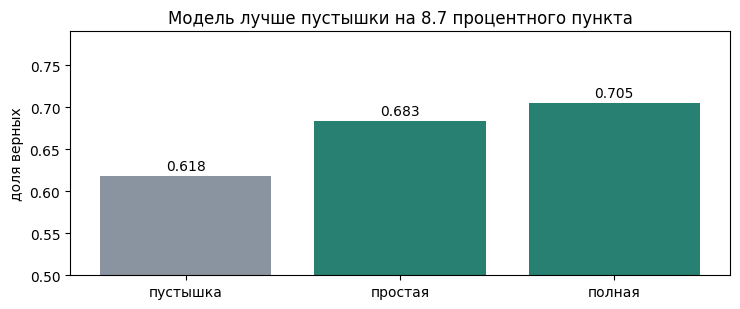

In [54]:
few_prep = make_prep(["age", "year"], flag_cols=["hired"])          # простая: 3 признака
full_prep = make_prep(num_cols, cat_cols, flag_cols, add_features=add_features, min_frequency=10)

ladder = pd.Series({
    "пустышка": cv_score(make_dummy(y), X_train, y_train),
    "простая": cv_score(make_model(few_prep, y), X_train, y_train),
    "полная": cv_score(make_model(full_prep, y), X_train, y_train),
})
print(ladder.round(3))
ladder_plot(ladder, y, path="figures/baseline.png")

In [55]:
final_model = make_model(full_prep, y).fit(X_train, y_train)
dummy_test = test_score(make_dummy(y).fit(X_train, y_train), X_test, y_test)
model_test = test_score(final_model, X_test, y_test)
print("test, пустышка:", round(dummy_test, 3))
print("test, модель:  ", round(model_test, 3))

test, пустышка: 0.618
test, модель:   0.709


**Вывод.** Пустышка «никто не дойдёт» угадывает 61,8%. Простая модель на трёх признаках (возраст, год, нанят) даёт 68,3%, полная модель 70,5% на кросс-валидации. На test, один раз в конце, полная модель угадывает 70,9% против 61,8% у пустышки: на 9,1 процентного пункта лучше. Кросс-валидация (70,5%) и test (70,9%) почти совпали, значит, оценка честная, без утечки.

---
## 14. Выводы

**Что сделать.** 3-5 пунктов с числами: что узнали о данных, насколько модель лучше пустышки, что сработало, что бы сделали дальше. Выводы читает человек, который не открывал тетрадь.

**Где посмотреть:** практика 12, раздел 9.2; образец, раздел 14.



**Выводы.**

1. До вершины доходят 38,2% участников, поэтому пустышка «никто не дойдёт» уже угадывает 61,8%. Честная модель угадывает 70,9% на test, на 9,1 п.п. лучше.
2. Самые сильные честные сигналы: эпоха (после 2000 года успех 46,5% против 25,5%), гражданство Непала (62,7% против 31,6%) и сезон (весна и осень 38,7% против 24,5%).
3. Две утечки найдены и убраны: высшая точка (с ней 95,1% верных) и кислород (+6,8 п.п.), оба известны только во время или после восхождения.
4. Подготовка учится только на train внутри Pipeline, поэтому кросс-валидация (70,5%) и test (70,9%) совпали.
5. Дальше я бы добавил данные об экспедиции из таблицы expeditions.csv (размер команды, число шерпов, коммерческая ли экспедиция), но посчитанные только на train, и попробовал модель-дерево: она сама находит сочетания вроде «Эверест + весна».

## 15. README  ·  вместе с выводами: 15 баллов

**Что сделать.** README по шаблону из ТЗ: задача, данные, что сделано (журнал), главное из EDA, утечка, результаты, выводы, как запустить. Журнал, лестницу и test удобно вставить из переменных тетради f-строкой: тогда числа в README совпадают с тетрадью.

**Где посмотреть:** практика 12, раздел 9.3; образец, раздел 15 и его `README.md`.

По желанию, без баллов: сохранить модель, `joblib.dump(final_model, "model/model.joblib")`, и написать в README, как её загрузить.

README.md написан по шаблону ТЗ, числа взяты из разделов 12 и 13.

---



---
## 16. Финальная проверка  ·  15 баллов

1. `write_requirements()` создаёт `requirements.txt`.
2. «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь проходит сверху вниз без единой ошибки.
3. Сохраните тетрадь после запуска и скачайте: «Файл», затем «Скачать», затем «Скачать .ipynb», имя `project.ipynb`.
4. Обновите репозиторий: «Add file», затем «Upload files», перетащите `project.ipynb`, `README.md`, `requirements.txt` и папки `figures` (и `model`, если сохраняли). Подпись коммита «этап 2: признаки, утечка, baseline», затем «Commit changes». Тетрадь можно обновить и из Colab: «Файл», затем «Сохранить копию на GitHub».
5. Откройте ссылку в режиме инкогнито: README на главной, тетрадь открывается, графики видны.

**Чек-лист перед сдачей**

* [ ] раздел 9 этапа 1 доведён, замечания по этапу 1 исправлены;
* [ ] минимум 3 новых признака, у каждого «зачем»;
* [ ] в признаках только числа и ни одного пропуска;
* [ ] таблица утечек и проверка моделью;
* [ ] пустышка, простая и полная модель, кросс-валидация на train, график;
* [ ] test тронут один раз, в самом конце;
* [ ] под каждым разделом «Вывод»;
* [ ] README по шаблону, числа совпадают с тетрадью;
* [ ] `requirements.txt` в репозитории;
* [ ] тетрадь проходит «Перезапустить сеанс и выполнить все» и сохранена с выводами;
* [ ] ссылка открывается в режиме инкогнито.

In [56]:
write_requirements()

pandas==2.2.3
numpy==2.4.6
scikit-learn==1.6.1
matplotlib==3.10.0
joblib==1.6.0


**Вывод.** `requirements.txt` создан с версиями библиотек. Тетрадь проходит «Перезапустить сеанс и выполнить все» без ошибок и сохранена с выводами ячеек. Репозиторий обновлён: тетрадь, README, requirements, данные и график.